In [8]:
# Run once, then restart your Jupyter kernel before proceeding.
%pip install torch torchvision pillow pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [9]:
from pathlib import Path
import urllib.request
import math
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display
from torchvision.models.detection import (
    ssdlite320_mobilenet_v3_large,
    SSDLite320_MobileNet_V3_Large_Weights,
)
print('PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
Path('images').mkdir(exist_ok=True)
Path('outputs').mkdir(exist_ok=True)

PyTorch: 2.14.0+cpu | Torchvision: 0.29.0+cpu
Device: cpu


In [10]:
weights = SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
model = ssdlite320_mobilenet_v3_large(weights=weights).to(DEVICE).eval()
preprocess = weights.transforms()
categories = weights.meta['categories']
print('Supported labels:')
print(', '.join(c for c in categories if c not in ['N/A', '__background__']))

Supported labels:
person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe, backpack, umbrella, handbag, tie, suitcase, frisbee, skis, snowboard, sports ball, kite, baseball bat, baseball glove, skateboard, surfboard, tennis racket, bottle, wine glass, cup, fork, knife, spoon, bowl, banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake, chair, couch, potted plant, bed, dining table, toilet, tv, laptop, mouse, remote, keyboard, cell phone, microwave, oven, toaster, sink, refrigerator, book, clock, vase, scissors, teddy bear, hair drier, toothbrush


Image size: (1546, 1213)


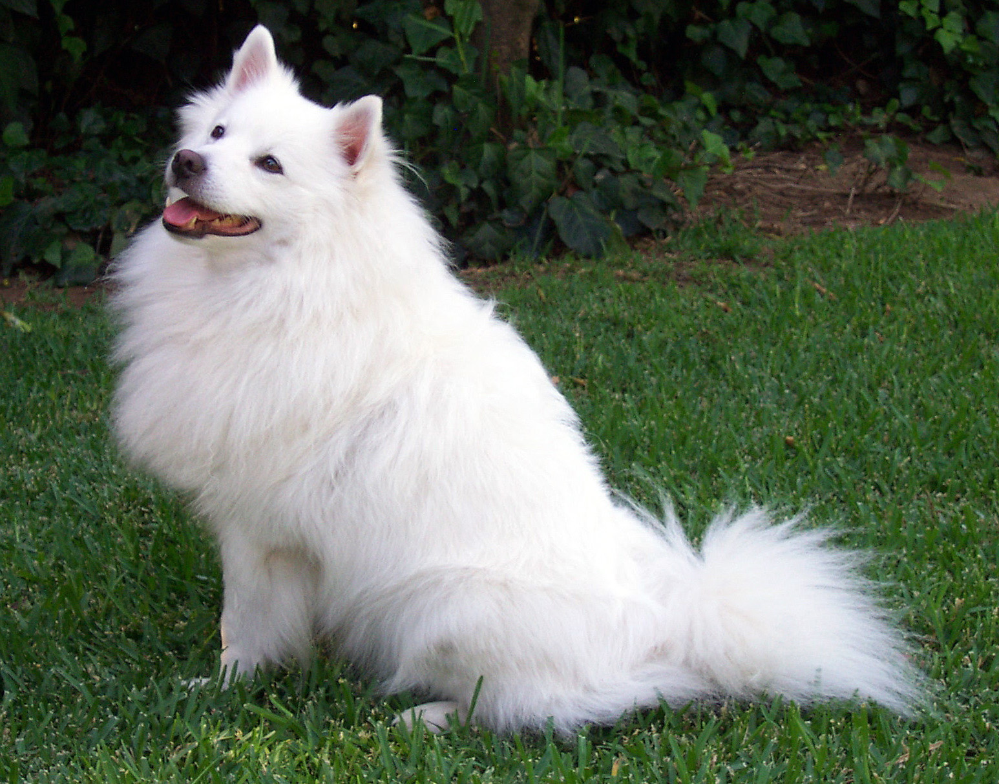

In [11]:
IMAGE_PATH = Path('images/sample_dog.jpg')
DOWNLOAD_SAMPLE = True
SAMPLE_URL = 'https://github.com/pytorch/hub/raw/master/images/dog.jpg'
if DOWNLOAD_SAMPLE and not IMAGE_PATH.exists():
    IMAGE_PATH.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(SAMPLE_URL, headers={'User-Agent': 'Jupyter-Object-Detection'})
    with urllib.request.urlopen(request, timeout=60) as response:
        raw_image = response.read()
    # Validate before saving; network error pages must not become image files.
    from io import BytesIO
    with Image.open(BytesIO(raw_image)) as sample:
        sample.verify()
    IMAGE_PATH.write_bytes(raw_image)
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f'Image not found: {IMAGE_PATH.resolve()}')
with Image.open(IMAGE_PATH) as source:
    image = ImageOps.exif_transpose(source).convert('RGB')
print('Image size:', image.size)
display(image)

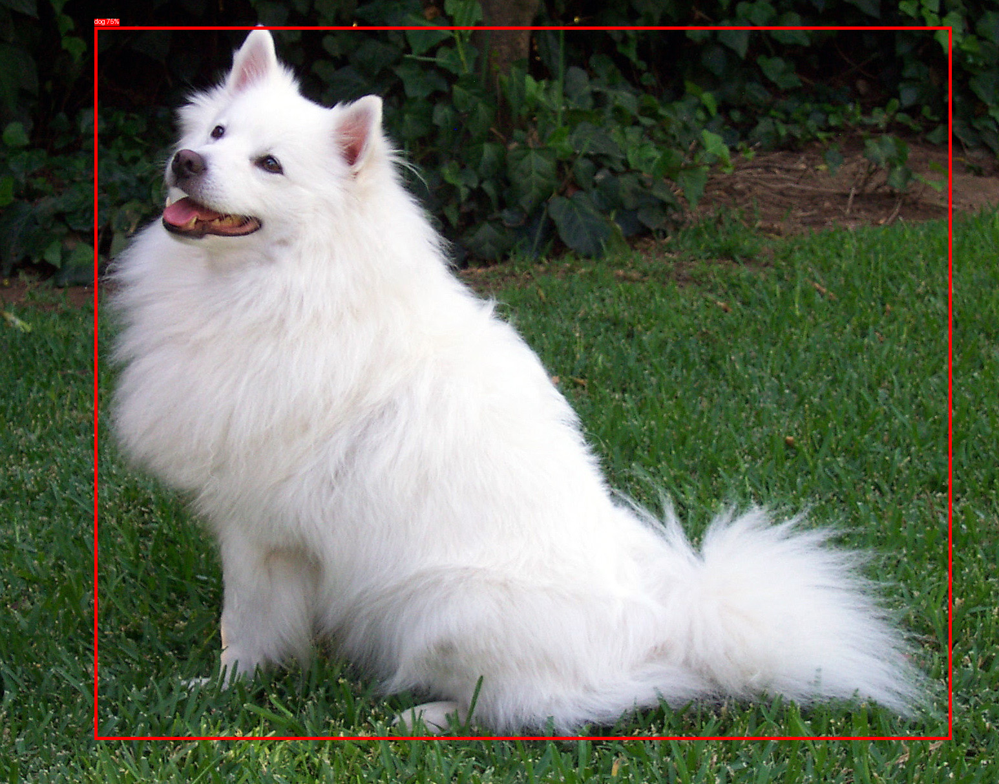

,class_id,object,confidence,xmin,ymin,xmax,ymax
0,18,dog,0.749296,146.855011,41.291298,1472.187012,1144.476929


,object,count
0,dog,1


In [12]:
COLUMNS = ['class_id', 'object', 'confidence', 'xmin', 'ymin', 'xmax', 'ymax']

def detect_objects(pil_image, threshold=0.5):
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError('Threshold must be between 0 and 1.')
    rgb = pil_image.convert('RGB')
    tensor = preprocess(rgb).to(DEVICE)
    with torch.inference_mode():
        result = model([tensor])[0]
    rows = []
    for box, label, score in zip(result['boxes'].cpu().tolist(), result['labels'].cpu().tolist(), result['scores'].cpu().tolist()):
        if score >= threshold:
            rows.append(dict(class_id=label, object=categories[label], confidence=score,
                             xmin=box[0], ymin=box[1], xmax=box[2], ymax=box[3]))
    table = pd.DataFrame(rows, columns=COLUMNS)
    annotated = rgb.copy()
    draw = ImageDraw.Draw(annotated)
    font = ImageFont.load_default()
    for row in rows:
        box = (row['xmin'], row['ymin'], row['xmax'], row['ymax'])
        draw.rectangle(box, outline='red', width=max(2, rgb.width // 300))
        label_text = f"{row['object']} {row['confidence']:.0%}"
        x = max(0, int(row['xmin']))
        y = max(0, int(row['ymin']) - 14)
        text_box = draw.textbbox((x, y), label_text, font=font)
        draw.rectangle(text_box, fill='red')
        draw.text((x, y), label_text, fill='white', font=font)
    return annotated, table

CONFIDENCE_THRESHOLD = 0.5
annotated, detections = detect_objects(image, CONFIDENCE_THRESHOLD)
display(annotated)
display(detections)
if detections.empty:
    print('No objects passed the threshold. Try a clearer image or a lower threshold.')
else:
    display(detections.groupby('object').size().rename('count').reset_index())

In [13]:
annotated.save('outputs/detected_image.jpg')
detections.to_csv('outputs/detections.csv', index=False)
print('Saved outputs/detected_image.jpg and outputs/detections.csv')

Saved outputs/detected_image.jpg and outputs/detections.csv


In [14]:
all_rows = []
for path in sorted(Path('images').iterdir()):
    if path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
        continue
    try:
        with Image.open(path) as source:
            current = ImageOps.exif_transpose(source).convert('RGB')
        result_image, result_table = detect_objects(current, CONFIDENCE_THRESHOLD)
        result_image.save(Path('outputs') / f'{path.name}_detected.jpg')
        result_table.insert(0, 'file', path.name)
        all_rows.append(result_table)
        print(path.name, ':', len(result_table), 'detections')
    except (OSError, ValueError, RuntimeError) as exc:
        print('Could not process', path.name, ':', exc)
batch = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame(columns=['file'] + COLUMNS)
batch.to_csv('outputs/batch_detections.csv', index=False)
display(batch.head(20))

sample_dog.jpg : 1 detections


,file,class_id,object,confidence,xmin,ymin,xmax,ymax
0,sample_dog.jpg,18,dog,0.749296,146.855011,41.291298,1472.187012,1144.476929
